<a href="https://colab.research.google.com/github/Goat-Seller/bankruptcy-prediction/blob/main/lab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Task 2.1

In [ ]:
import pandas as pd, numpy as np, seaborn as sns

sns.set_theme()
data = pd.read_csv('/content/drive/MyDrive/exercise_dataset.csv')

data.head()

,ID,Exercise,Calories Burn,Dream Weight,Actual Weight,Age,Gender,Duration,Heart Rate,BMI,Weather Conditions,Exercise Intensity
0,1,Exercise 2,286.959851,91.892531,96.301115,45,Male,37,170,29.426275,Rainy,5
1,2,Exercise 7,343.453036,64.165097,61.104668,25,Male,43,142,21.286346,Rainy,5
2,3,Exercise 4,261.223465,70.846224,71.766724,20,Male,20,148,27.899592,Cloudy,4
3,4,Exercise 5,127.183858,79.477008,82.984456,33,Male,39,170,33.729552,Sunny,10
4,5,Exercise 10,416.318374,89.960226,85.643174,29,Female,34,118,23.286113,Cloudy,3


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3864 entries, 0 to 3863
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  3864 non-null   int64  
 1   Exercise            3864 non-null   object 
 2   Calories Burn       3864 non-null   float64
 3   Dream Weight        3864 non-null   float64
 4   Actual Weight       3864 non-null   float64
 5   Age                 3864 non-null   int64  
 6   Gender              3864 non-null   object 
 7   Duration            3864 non-null   int64  
 8   Heart Rate          3864 non-null   int64  
 9   BMI                 3864 non-null   float64
 10  Weather Conditions  3864 non-null   object 
 11  Exercise Intensity  3864 non-null   int64  
dtypes: float64(4), int64(5), object(3)
memory usage: 362.4+ KB


In [ ]:
data.describe()

,ID,Calories Burn,Dream Weight,Actual Weight,Age,Duration,Heart Rate,BMI,Exercise Intensity
count,3864.000000,3864.000000,3864.000000,3864.000000,3864.000000,3864.000000,3864.000000,3864.000000,3864.000000
mean,1932.500000,301.861806,75.139263,75.188440,39.621118,40.190994,139.777950,26.801977,5.457298
std,1115.585048,115.828604,14.545824,14.845511,12.521721,11.765957,23.447528,4.746745,2.850896
min,1.000000,100.009403,50.001984,45.783747,18.000000,20.000000,100.000000,18.500014,1.000000
25%,966.750000,202.168837,62.373585,62.476906,29.000000,30.000000,119.000000,22.686774,3.000000
50%,1932.500000,299.742508,75.522136,75.544407,40.000000,40.000000,140.000000,26.861656,5.000000
75%,2898.250000,404.143688,87.707989,88.105767,51.000000,51.000000,160.000000,30.950380,8.000000
max,3864.000000,499.859262,99.985355,104.309600,60.000000,60.000000,180.000000,34.996639,10.000000


Features distribution


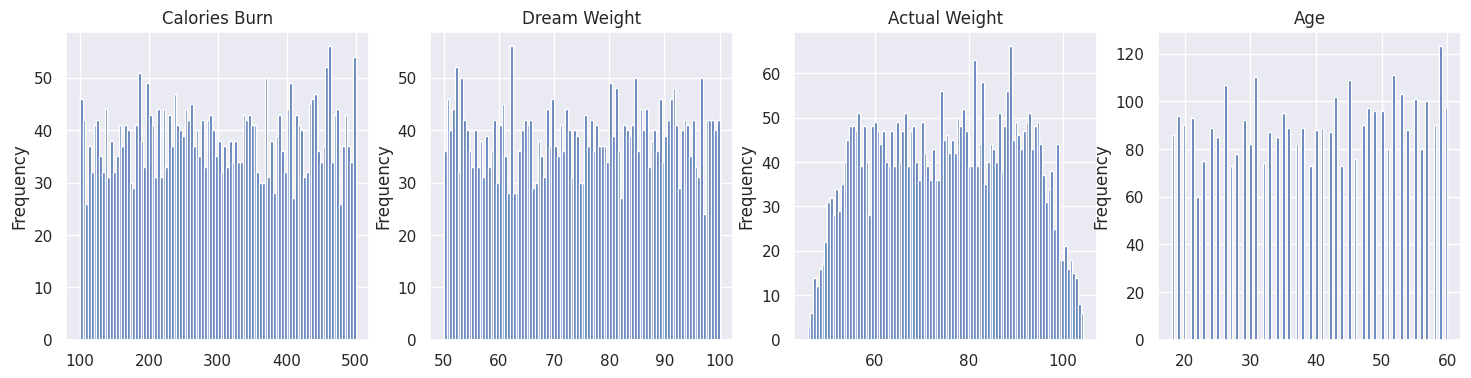

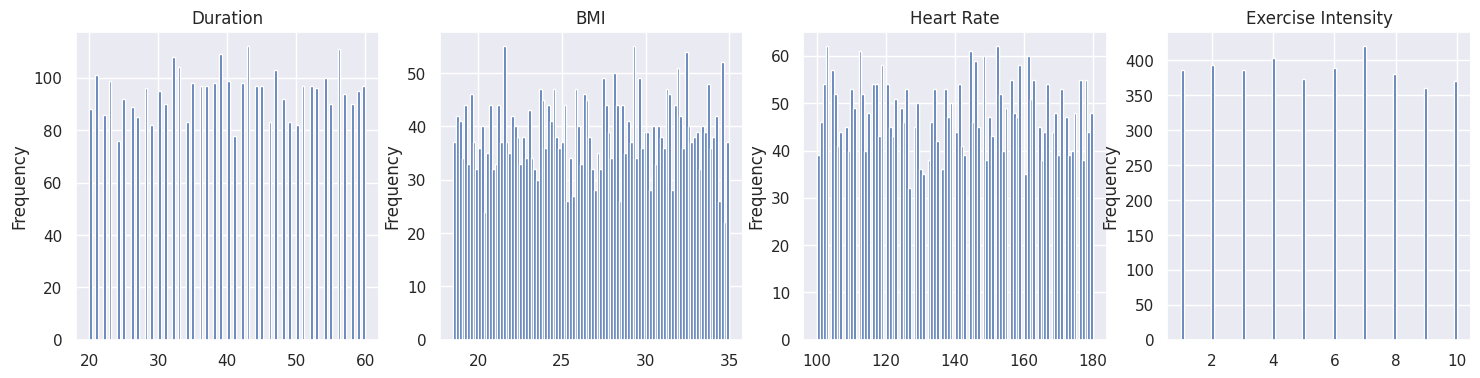

In [ ]:
import matplotlib.pyplot as plt
categories = ["Calories Burn", "Dream Weight", "Actual Weight", "Age",
              "Duration", "BMI", "Heart Rate", "Exercise Intensity"]

for k in range(2):
    fig, plot = plt.subplots(1, 4, figsize=(18, 4))
    for i in range(4):
        col = categories[k * 4 + i]
        data[col].plot.hist(ax=plot[i], bins=100, title=col)
    plt.show()

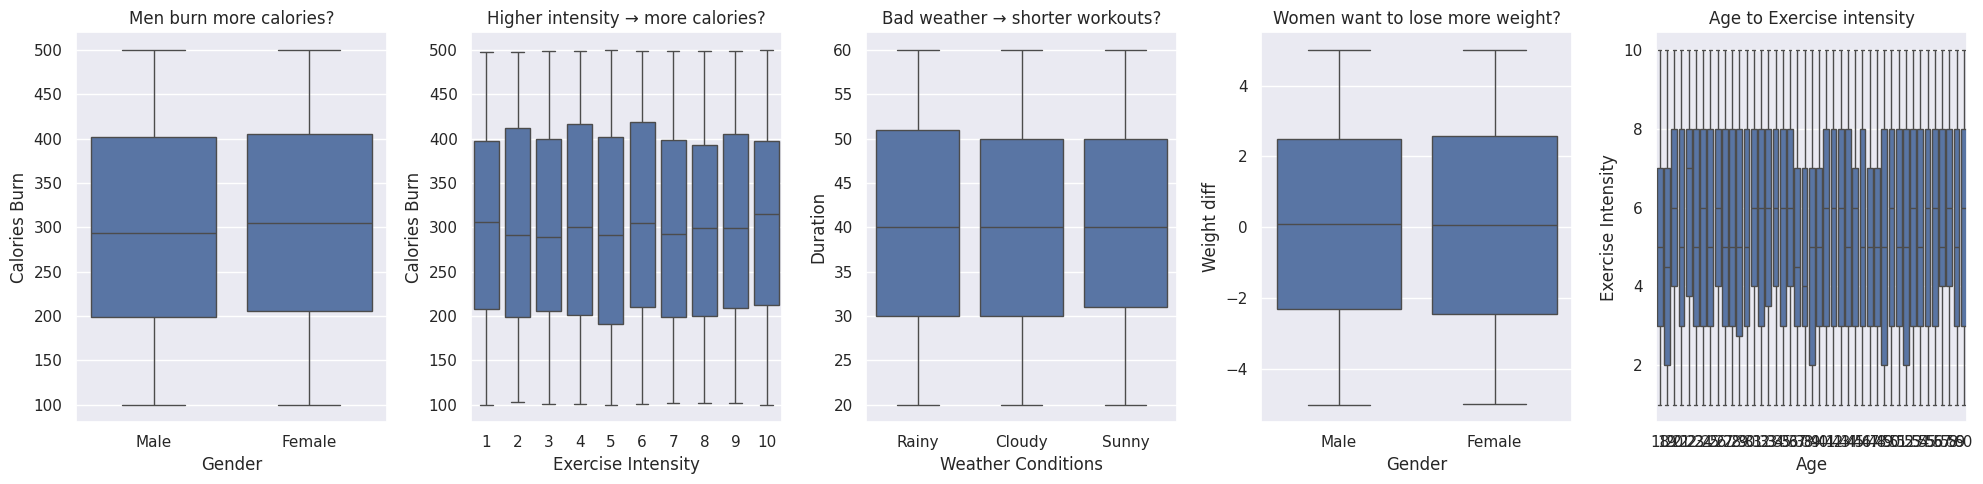

In [ ]:

fig, ax = plt.subplots(1, 5, figsize=(20, 5))

sns.boxplot(data=data, x="Gender", y="Calories Burn", ax=ax[0])
ax[0].set_title("Men burn more calories?")

sns.boxplot(data=data, x="Exercise Intensity", y="Calories Burn", ax=ax[1])
ax[1].set_title("Higher intensity → more calories?")

sns.boxplot(data=data, x="Weather Conditions", y="Duration", ax=ax[2])
ax[2].set_title("Bad weather → shorter workouts?")

data["Weight diff"] = data["Actual Weight"] - data["Dream Weight"]
sns.boxplot(data=data, x="Gender", y="Weight diff", ax=ax[3])
ax[3].set_title("Women want to lose more weight?")

data["Weight diff"] = data["Age"] - data["Exercise Intensity"]
sns.boxplot(data=data, x="Age", y="Exercise Intensity", ax=ax[4])
ax[4].set_title("Age to Exercise intensity")
plt.tight_layout()
plt.show()

The dataset is well distributed, no obvious outliers

Task 2.2


My biases and assumptions :
1. Lower BMI - > lower heart rate
2. Higher Exercise intensity - > higher calories burn and shorter duration
3. Higher age -> lower exercise intensity
4. Higher body weight, longer duration -> more calories burned
5. Higher heart rate -> shorter duration
6. Bad weather -> less exercise
7. Men burn more calories on average
8. Women will have a bigger difference between actual weight and dream weight

Task 2.3


Work done:


1. Beyond Raw Views: Bayesian Normalization

Libraries used:

pandas, NumPy: data loading, manipulation and numerical computation
SciPy (scipy.stats): statistical tests and probability distributions
statsmodels: statistical modelling and regression analysis
scikit-learn: BayesianRidge and Ridge regression models, R² and MSE evaluation metrics
matplotlib (pyplot, patches, gridspec): data visualisation and multi-panel figure layouts
seaborn: statistical plots
os, glob, dataclasses, typing (standard library): file handling and code structure

Goal: "viral" is defined as raw view count. The goal is to introduce a Scale-Invariant Outlier Index (SIOI) using Bayesian Hierarchical Mixed-Effects
Example:
an 800 thousand subs channel gets 400 tsd. views. It is labeled as viral even though it underperforms the channel average

Conclusions: raw virality mostly reflects channel size. After normalisation, virality is independent of channel size and similar across categories, and thumbnails with faces perform slightly better.

2. Stop Predicting Virality with Likes: The Post-Hoc

libraries used:

same as above

Goal :  show that models predicting virality from likes, comments and shares suffer from data leakage, since these metrics are only known after upload, and build a leak-free baseline that uses only information available before upload.


Conclusions: the very high results reported by other notebooks (AUC > 0.98, R² > 0.95) are caused by leakage. The clean pre-upload model reaches about 0.90 ROC-AUC, channel size is the main driver of virality, and thumbnails with faces help slightly.

3. What Makes a YouTube Video Go Viral?

Libraries:

same as example 1

Goal: a general analysis of what is associated with high video popularity (engagement, titles and tags, publishing time)

Conclusions: no conclusions are reported, because no output is shared. The author only notes that no single factor guarantees virality, and that popularity also depends on audience, niche, creator reach, timing and the recommendation algorithm.



Task 2.5


In [ ]:
import pandas as pd, numpy as np, seaborn as sns

sns.set_theme()
data = pd.read_csv('/content/drive/MyDrive/exercise_dataset.csv')

data.head()

Task 2.6

In [ ]:
from google.colab import drive

from sklearn.model_selection import train_test_split
data = pd.read_csv('/content/data.csv')
train, test = train_test_split(data, test_size=0.3, random_state=42)

print("Train (70%):", train.shape)
print("Test  (30%):", test.shape)

# save the test set and don't touch it until the end of the project
test.to_csv('/content/drive/MyDrive/test_data.csv', index=False)
train.to_csv('/content/drive/MyDrive/train_data.csv', index=False)

data = train      # from now on we work only on the 70%

Train (70%): (4773, 96)
Test  (30%): (2046, 96)


In [ ]:
data.head()

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
5632,0,0.500951,0.584169,0.553777,0.600614,0.600549,0.999025,0.797528,0.809438,0.303650,...,0.820175,0.002280,0.625785,0.600611,0.841847,0.278811,0.026855,0.565445,1,0.033673
903,0,0.479647,0.523932,0.530007,0.609666,0.609666,0.998971,0.797330,0.809240,0.303417,...,0.789320,0.001707,0.623430,0.609661,0.839409,0.281799,0.025910,0.539820,1,0.023831
2666,0,0.516502,0.580953,0.568714,0.610682,0.610682,0.999128,0.797571,0.809469,0.303510,...,0.826516,0.000909,0.624479,0.610681,0.841642,0.275619,0.026792,0.565164,1,0.113503
109,0,0.446302,0.531509,0.499545,0.595771,0.595771,0.998895,0.797324,0.809286,0.303565,...,0.794111,0.015785,0.623716,0.595770,0.839915,0.277858,0.026101,0.555682,1,0.040701
5316,0,0.501194,0.560565,0.547781,0.600001,0.600001,0.999034,0.797440,0.809349,0.303477,...,0.811586,0.002546,0.624576,0.600001,0.841244,0.279156,0.026794,0.565173,1,0.031863


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4773 entries, 5632 to 860
Data columns (total 96 columns):
 #   Column                                                    Non-Null Count  Dtype  
---  ------                                                    --------------  -----  
 0   Bankrupt?                                                 4773 non-null   int64  
 1    ROA(C) before interest and depreciation before interest  4773 non-null   float64
 2    ROA(A) before interest and % after tax                   4773 non-null   float64
 3    ROA(B) before interest and depreciation after tax        4773 non-null   float64
 4    Operating Gross Margin                                   4773 non-null   float64
 5    Realized Sales Gross Margin                              4773 non-null   float64
 6    Operating Profit Rate                                    4773 non-null   float64
 7    Pre-tax net Interest Rate                                4773 non-null   float64
 8    After-tax net Intere

The more you borrow, the more likely you are to go bankrupt
do companies that have lower net value per share tend to be unprofitable

What is the least amount of features to predict bankrupcy.

Features to hypothesis
1. ROA (A)
2. Research and development expense rate
3. Revenue Per Share (Yuan ¥)
4. Total debt/Total net worth                        
5. Debt ratio %
6. Cash Flow to Liability
7. urrent Liability to Equity
8. Net Income to Total Assets
9. Borrowing dependency
10. Allocation rate per person


In [ ]:
data.describe()

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
count,4773.000000,4773.000000,4773.000000,4773.000000,4773.000000,4773.000000,4773.000000,4773.000000,4773.000000,4773.000000,...,4773.000000,4.773000e+03,4773.000000,4773.000000,4773.000000,4773.000000,4773.000000,4773.000000,4773.0,4773.000000
mean,0.029751,0.506072,0.559507,0.554408,0.607956,0.607942,0.998876,0.797271,0.809140,0.303511,...,0.808175,1.739661e+07,0.623928,0.607955,0.840376,0.280297,0.027675,0.565311,1.0,0.048156
std,0.169917,0.061579,0.066240,0.062335,0.016953,0.016937,0.005698,0.010144,0.012400,0.008725,...,0.041235,3.765608e+08,0.014025,0.016953,0.015853,0.011386,0.018473,0.012998,0.0,0.052477
min,0.000000,0.000000,0.006923,0.000000,0.000000,0.000000,0.612132,0.160516,0.000000,0.000000,...,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.133503,0.000000,0.000000,1.0,0.000000
25%,0.000000,0.476820,0.536143,0.527544,0.600492,0.600499,0.998971,0.797387,0.809313,0.303466,...,0.797064,9.110040e-04,0.623640,0.600492,0.840138,0.276928,0.026791,0.565158,1.0,0.024575
50%,0.000000,0.503778,0.560674,0.553188,0.606055,0.606055,0.999024,0.797466,0.809378,0.303525,...,0.810959,2.100891e-03,0.623878,0.606052,0.841202,0.278752,0.026809,0.565256,1.0,0.033942
75%,0.000000,0.536684,0.590166,0.584988,0.613867,0.613824,0.999097,0.797580,0.809471,0.303587,...,0.827049,5.242171e-03,0.624185,0.613863,0.842371,0.281417,0.026914,0.565732,1.0,0.053210
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.999778,1.000000,1.000000,0.730252,...,0.982879,9.820000e+09,1.000000,1.000000,1.000000,0.745352,1.000000,0.736985,1.0,1.000000


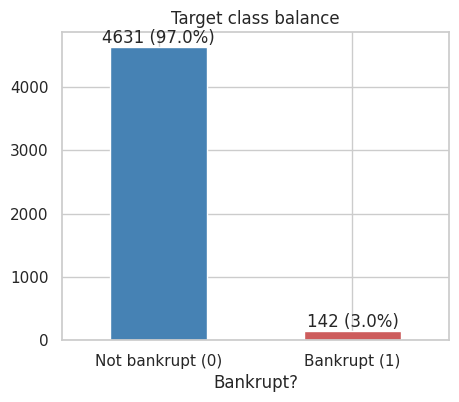

Binary flags: ['Liability-Assets Flag', 'Net Income Flag']
                       count  bankrupt rate
Liability-Assets Flag                      
0                       4768       0.029153
1                          5       0.600000 

                 count  bankrupt rate
Net Income Flag                      
1                 4773       0.029751 

Constant columns (no information): ['Net Income Flag']


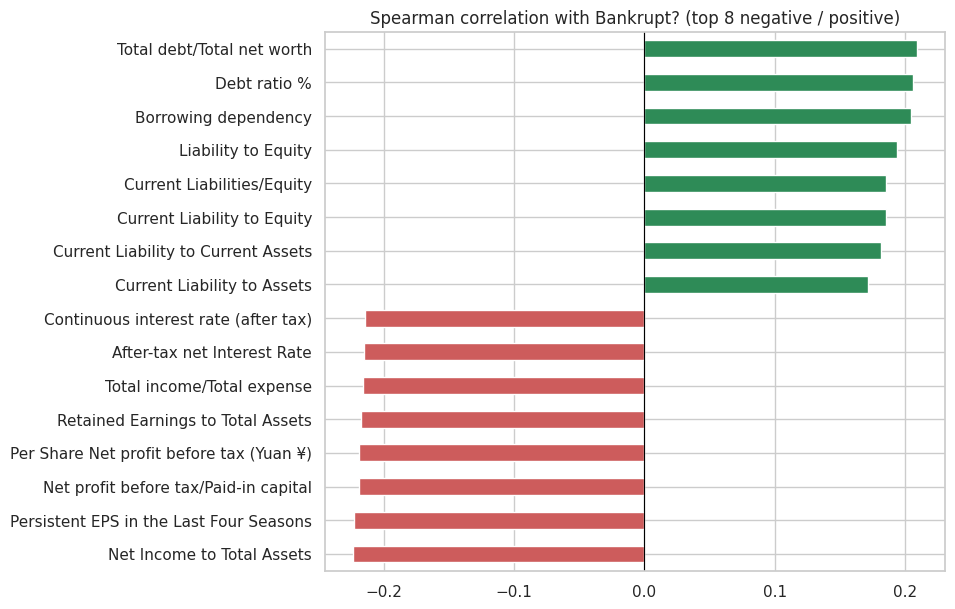

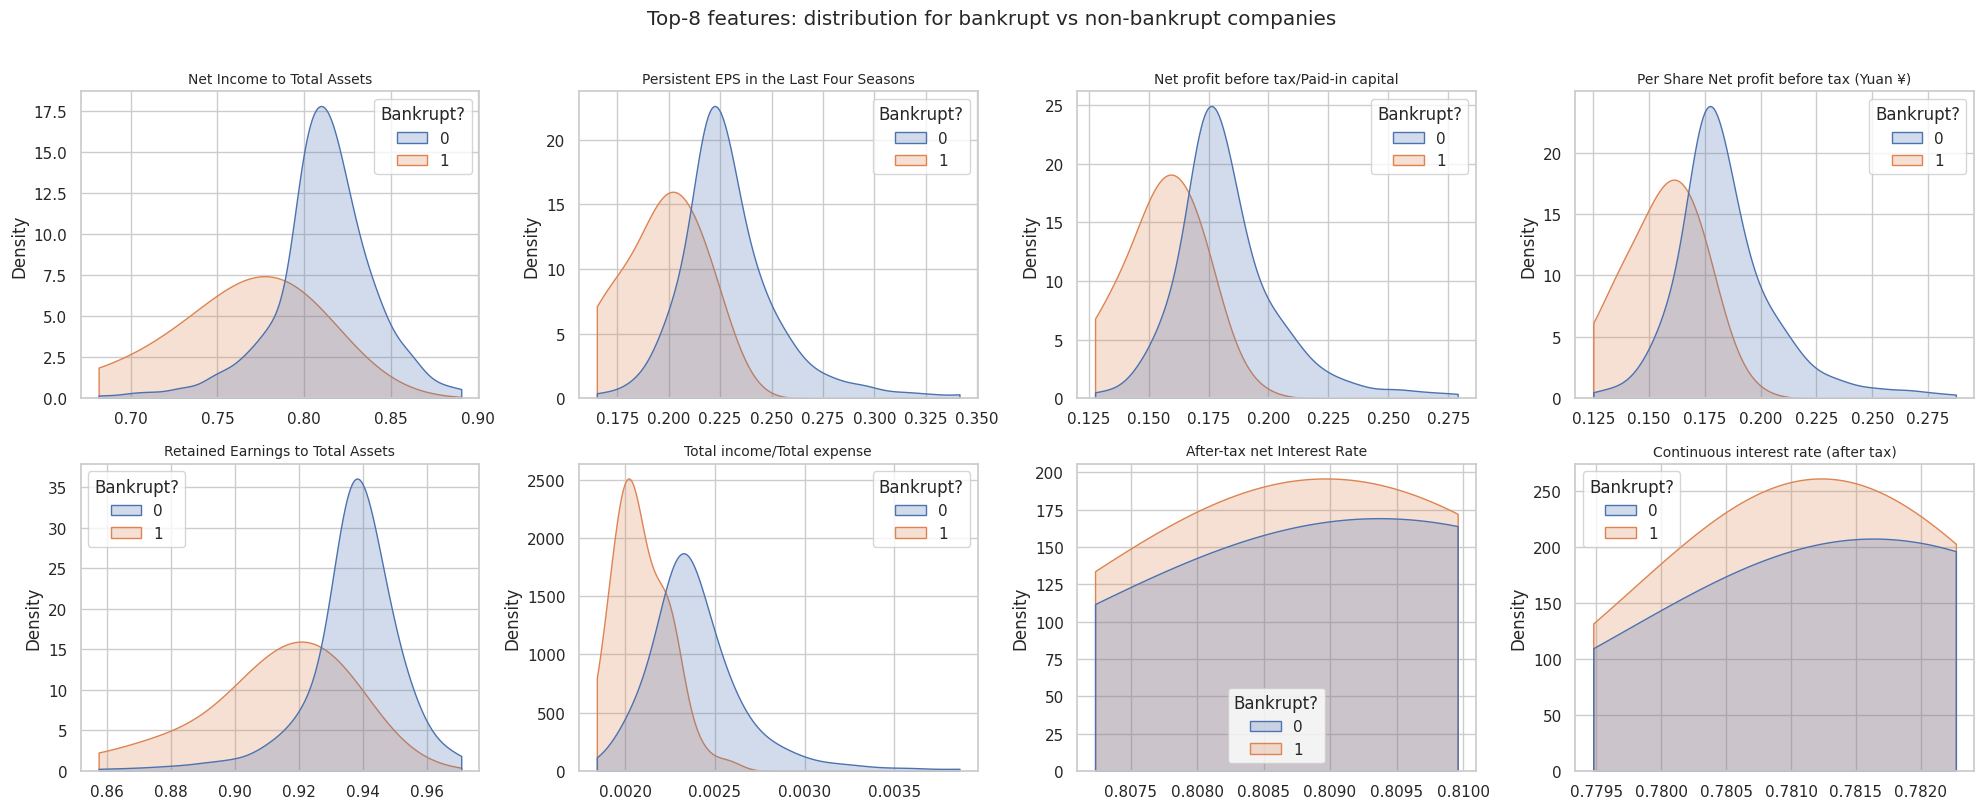

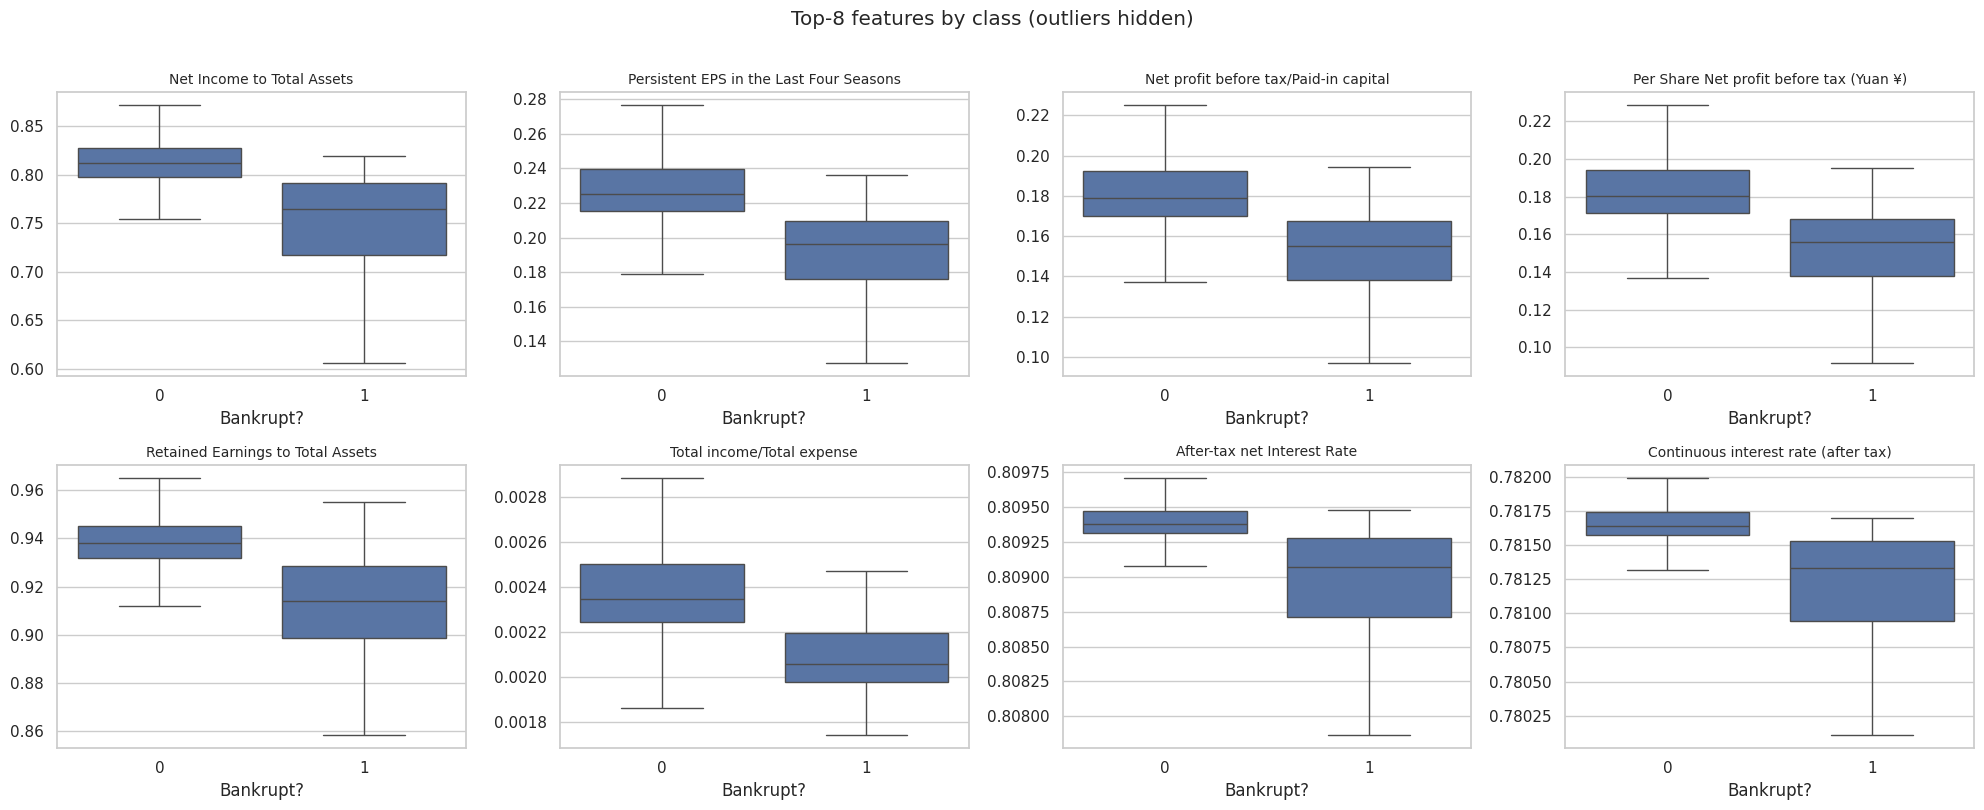

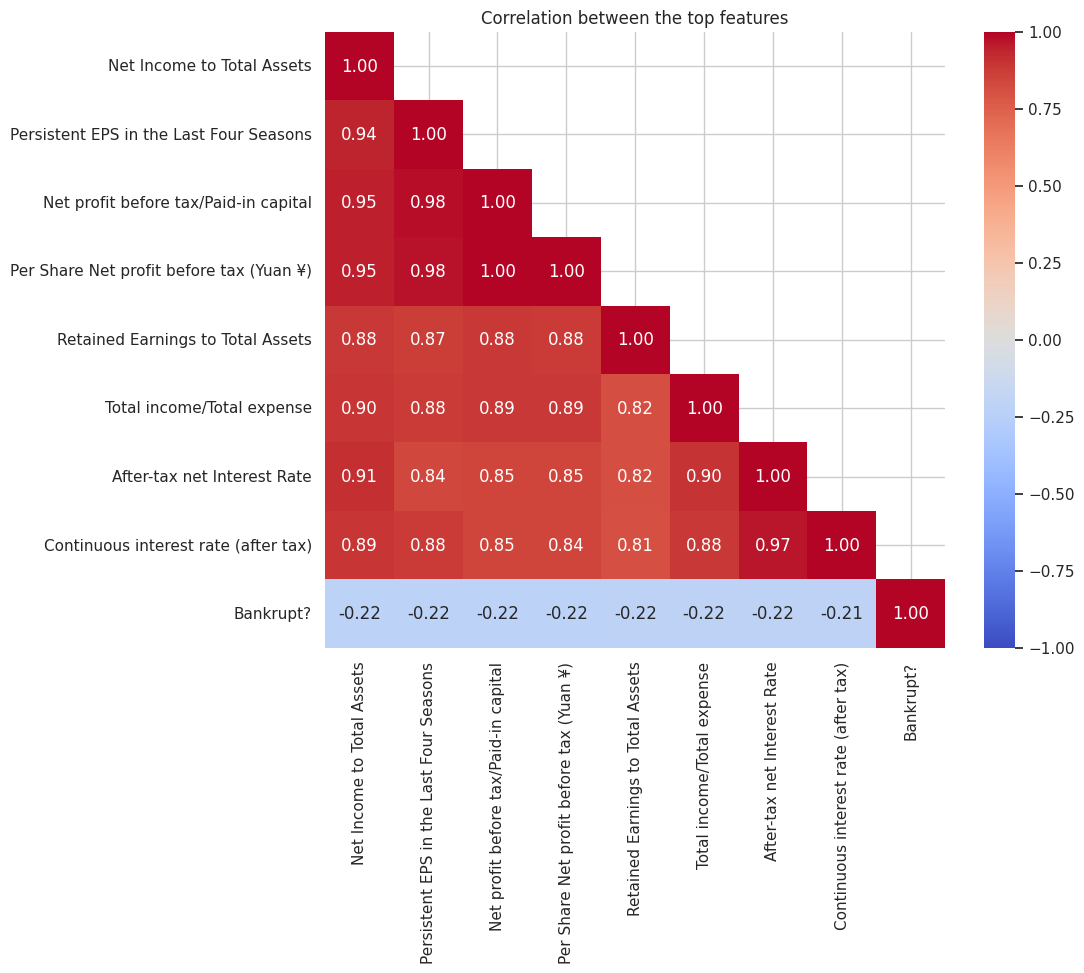

Feature pairs with |rho| > 0.9: 86
Current Liabilities/Equity     Current Liability to Equity            1.0
Current Liabilities/Liability  Current Liability to Liability         1.0
Debt ratio %                   Net worth/Assets                       1.0
Current Ratio                  Current Liability to Current Assets    1.0
Net worth/Assets               Equity to Liability                    1.0
Debt ratio %                   Equity to Liability                    1.0
Operating Gross Margin         Gross Profit to Sales                  1.0
Net Value Per Share (B)        Net Value Per Share (A)                1.0
Net Value Per Share (A)        Net Value Per Share (C)                1.0
Net Value Per Share (B)        Net Value Per Share (C)                1.0
dtype: float64


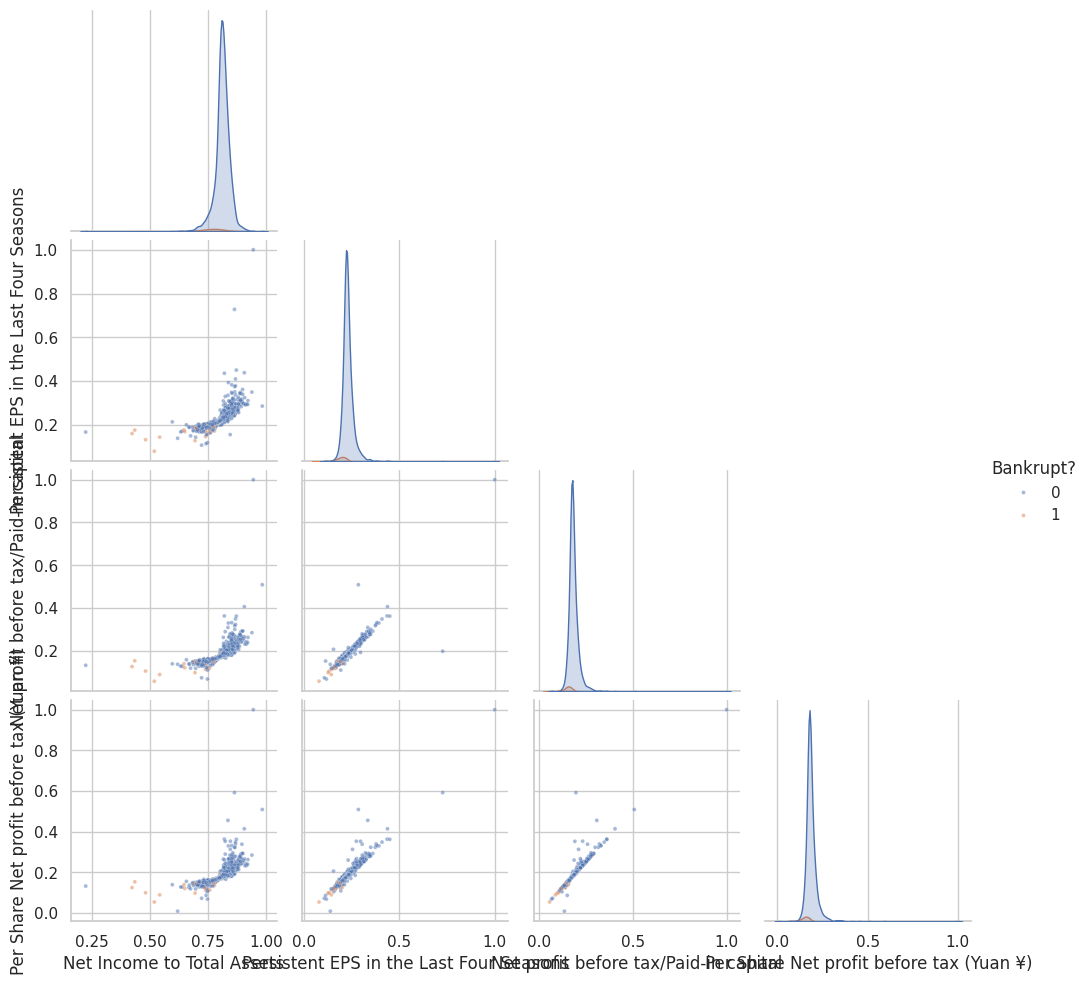

22 of 94 features exceed 1 (most are ratios scaled to 0–1):
                                          min           50%           max
Cash Turnover Rate                     0.0001  1.120000e+09  1.000000e+10
Quick Asset Turnover Rate              0.0001  2.213285e-04  1.000000e+10
Inventory Turnover Rate (times)        0.0000  7.258864e-04  9.990000e+09
Fixed Assets Turnover Frequency        0.0000  5.983897e-04  9.990000e+09
Operating Expense Rate                 0.0001  2.750992e-04  9.990000e+09
Total Asset Growth Rate                0.0000  6.440000e+09  9.990000e+09
Current Asset Turnover Rate            0.0000  1.979686e-04  9.990000e+09
Research and development expense rate  0.0000  5.090000e+08  9.980000e+09
Total debt/Total net worth             0.0000  5.516191e-03  9.940000e+09
Inventory/Current Liability            0.0000  6.366932e-03  9.910000e+09
Total assets to GNP price              0.0000  2.100891e-03  9.820000e+09
Accounts Receivable Turnover           0.0000  9.617

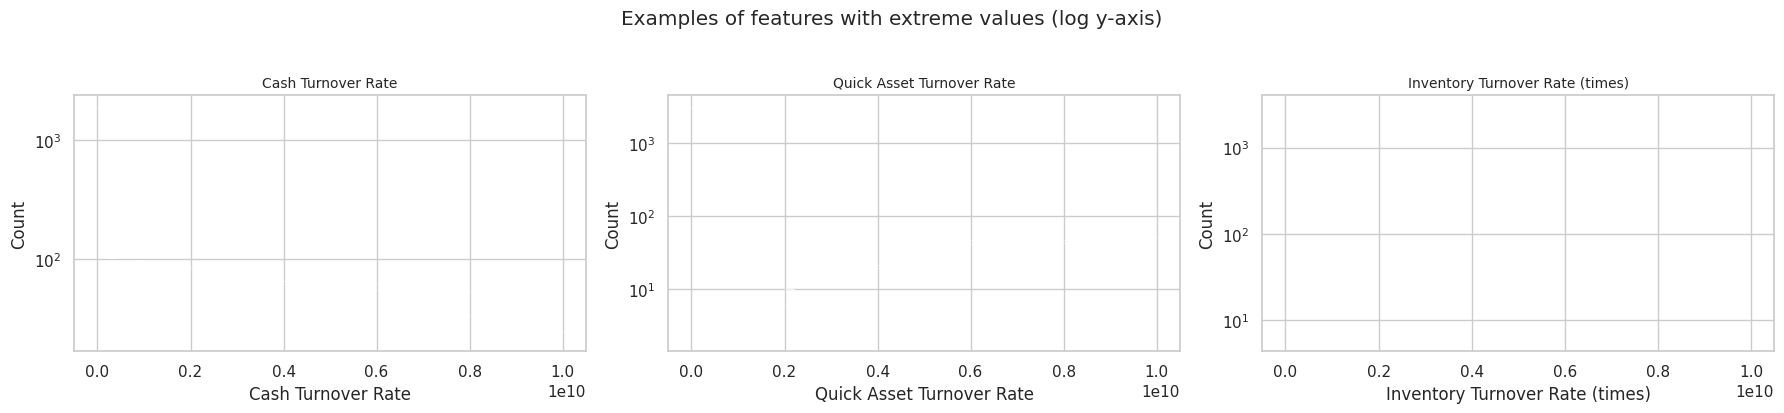

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")

# --- 0. Clean column names (they start with a space!) ---
data.columns = data.columns.str.strip()
target = "Bankrupt?"

# --- 1. Target balance ---
fig, ax = plt.subplots(figsize=(5, 4))
counts = data[target].value_counts().sort_index()
counts.plot.bar(ax=ax, color=["steelblue", "indianred"])
ax.set_xticklabels(["Not bankrupt (0)", "Bankrupt (1)"], rotation=0)
for i, v in enumerate(counts):
    ax.text(i, v, f"{v} ({v / len(data):.1%})", ha="center", va="bottom")
ax.set_title("Target class balance"); plt.show()

# --- 2. Binary flags and constant columns ---
binary = [c for c in data.columns if data[c].nunique() <= 2 and c != target]
print("Binary flags:", binary)
for c in binary:
    print(data.groupby(c)[target].agg(["count", "mean"]).rename(columns={"mean": "bankrupt rate"}), "\n")
constant = [c for c in data.columns if data[c].nunique() == 1]
print("Constant columns (no information):", constant)

# --- 3. Features most correlated with bankruptcy ---
features = [c for c in data.columns if c != target and c not in constant]
corr_t = data[features].corrwith(data[target], method="spearman").sort_values()
top = pd.concat([corr_t.head(8), corr_t.tail(8)])
plt.figure(figsize=(8, 7))
top.plot.barh(color=["indianred" if v < 0 else "seagreen" for v in top])
plt.title("Spearman correlation with Bankrupt? (top 8 negative / positive)")
plt.axvline(0, color="black", lw=0.8); plt.show()

# --- 4. Distributions of top features by class ---
top8 = corr_t.abs().sort_values(ascending=False).head(8).index.tolist()
fig, ax = plt.subplots(2, 4, figsize=(20, 8)); ax = ax.flatten()
for i, c in enumerate(top8):
    sns.kdeplot(data=data, x=c, hue=target, common_norm=False, fill=True, ax=ax[i], clip=data[c].quantile([0.01, 0.99]).values)
    ax[i].set_title(c, fontsize=10); ax[i].set_xlabel("")
plt.suptitle("Top-8 features: distribution for bankrupt vs non-bankrupt companies", y=1.01)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(2, 4, figsize=(20, 8)); ax = ax.flatten()
for i, c in enumerate(top8):
    sns.boxplot(data=data, x=target, y=c, ax=ax[i], showfliers=False)
    ax[i].set_title(c, fontsize=10); ax[i].set_xlabel("Bankrupt?"); ax[i].set_ylabel("")
plt.suptitle("Top-8 features by class (outliers hidden)", y=1.01)
plt.tight_layout(); plt.show()

# --- 5. Correlations between features (redundancy) ---
cm = data[top8 + [target]].corr(method="spearman")
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, mask=np.triu(np.ones_like(cm, bool), 1))
plt.title("Correlation between the top features"); plt.show()

full_corr = data[features].corr(method="spearman").abs()
pairs = full_corr.where(np.triu(np.ones_like(full_corr, bool), 1)).stack()
print(f"Feature pairs with |rho| > 0.9: {(pairs > 0.9).sum()}")
print(pairs.sort_values(ascending=False).head(10).round(3))

# --- 6. Pairplot of 4 strongest features ---
sns.pairplot(data[top8[:4] + [target]].sample(min(2000, len(data)), random_state=0),
             hue=target, corner=True, plot_kws={"s": 8, "alpha": 0.5})
plt.show()

# --- 7. Outliers / scale problems ---
desc = data[features].describe().T
weird = desc[desc["max"] > 1].sort_values("max", ascending=False)
print(f"{len(weird)} of {len(features)} features exceed 1 (most are ratios scaled to 0–1):")
print(weird[["min", "50%", "max"]].head(15))
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for a, c in zip(ax, weird.index[:3]):
    sns.histplot(data[c], bins=50, ax=a, log_scale=(False, True)); a.set_title(c, fontsize=10)
plt.suptitle("Examples of features with extreme values (log y-axis)", y=1.03); plt.tight_layout(); plt.show()